## Part I — CIFAR-10 CNN Training — ResNet20

In [80]:
import argparse
import os
import time
import shutil

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torch.backends.cudnn as cudnn

    

import torchvision
import torchvision.transforms as transforms

from models import *   # bring everything in the folder models

global best_prec
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_gpu = torch.cuda.is_available()
print('=> Building model...')
    
    
batch_size = 128

model_name = "resnet20"
model = resnet20_cifar()

        

normalize = transforms.Normalize(mean=[0.491, 0.482, 0.447], std=[0.247, 0.243, 0.262])


train_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        normalize,
    ]))
trainloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)


test_dataset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transforms.Compose([
        transforms.ToTensor(),
        normalize,
    ]))

testloader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)


print_freq = 100 # every 100 batches, accuracy printed. Here, each batch includes "batch_size" data points
# CIFAR10 has 50,000 training data, and 10,000 validation data.

def train(trainloader, model, criterion, optimizer, epoch):
    batch_time = AverageMeter()   ## at the begining of each epoch, this should be reset
    data_time = AverageMeter()
    losses = AverageMeter()
    top1 = AverageMeter()

    model.train()

    end = time.time()  # measure current time
    
    for i, (input, target) in enumerate(trainloader):
        # measure data loading time
        data_time.update(time.time() - end)  # data loading time

        input, target = input.to(device), target.to(device)

        # compute output
        output = model(input)
        loss = criterion(output, target)

        # measure accuracy and record loss
        prec = accuracy(output, target)[0]
        losses.update(loss.item(), input.size(0))
        top1.update(prec.item(), input.size(0))

        # compute gradient and do SGD step
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # measure elapsed time
        batch_time.update(time.time() - end) # time spent to process one batch
        end = time.time()


        if i % print_freq == 0:
            print('Epoch: [{0}][{1}/{2}]\t'
                  'Time {batch_time.val:.3f} ({batch_time.avg:.3f})\t'
                  'Data {data_time.val:.3f} ({data_time.avg:.3f})\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec {top1.val:.3f}% ({top1.avg:.3f}%)'.format(
                   epoch, i, len(trainloader), batch_time=batch_time,
                   data_time=data_time, loss=losses, top1=top1))

            

def validate(val_loader, model, criterion ):
    batch_time = AverageMeter()
    losses = AverageMeter()
    top1 = AverageMeter()

    # switch to evaluate mode
    model.eval()

    end = time.time()
    with torch.no_grad():
        for i, (input, target) in enumerate(val_loader):
         
            input, target = input.to(device), target.to(device)

            # compute output
            output = model(input)
            loss = criterion(output, target)

            # measure accuracy and record loss
            prec = accuracy(output, target)[0]
            losses.update(loss.item(), input.size(0))
            top1.update(prec.item(), input.size(0))

            # measure elapsed time
            batch_time.update(time.time() - end)
            end = time.time()

            if i % print_freq == 0:  # This line shows how frequently print out the status. e.g., i%5 => every 5 batch, prints out
                print('Test: [{0}/{1}]\t'
                  'Time {batch_time.val:.3f} ({batch_time.avg:.3f})\t'
                  'Loss {loss.val:.4f} ({loss.avg:.4f})\t'
                  'Prec {top1.val:.3f}% ({top1.avg:.3f}%)'.format(
                   i, len(val_loader), batch_time=batch_time, loss=losses,
                   top1=top1))

    print(' * Prec {top1.avg:.3f}% '.format(top1=top1))
    return top1.avg


def accuracy(output, target, topk=(1,5)):
    """Computes the precision@k for the specified values of k"""
    maxk = max(topk) # 5
    batch_size = target.size(0) # 128

    _, pred = output.topk(maxk, 1, True, True) # topk(k, dim=None, largest=True, sorted=True)
                                    # will output (max value, its index)
    pred = pred.t()               # transpose
    correct = pred.eq(target.view(1, -1).expand_as(pred))   # "-1": calculate automatically

    res = []
    for k in topk: # 1, 5
        correct_k = correct[:k].reshape(-1).float().sum(0)  # view(-1): make a flattened 1D tensor
        res.append(correct_k.mul_(100.0 / batch_size))   # correct: size of [maxk, batch_size]
    return res


class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n    ## n is impact factor
        self.count += n
        self.avg = self.sum / self.count

        
def save_checkpoint(state, is_best, fdir):
    filepath = os.path.join(fdir, 'checkpoint.pth')
    torch.save(state, filepath)
    if is_best:
        shutil.copyfile(filepath, os.path.join(fdir, 'model_best.pth.tar'))


def adjust_learning_rate(optimizer, epoch):
    """For resnet, the lr starts from 0.1, and is divided by 10 at 80 and 120 epochs"""
    adjust_list = [150, 225]
    if epoch in adjust_list:
        for param_group in optimizer.param_groups:
            param_group['lr'] = param_group['lr'] * 0.1        

#model = nn.DataParallel(model).cuda()
#all_params = checkpoint['state_dict']
#model.load_state_dict(all_params, strict=False)
#criterion = nn.CrossEntropyLoss().cuda()
#validate(testloader, model, criterion)

=> Building model...
Files already downloaded and verified
Files already downloaded and verified


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.49392712..1.5658436].


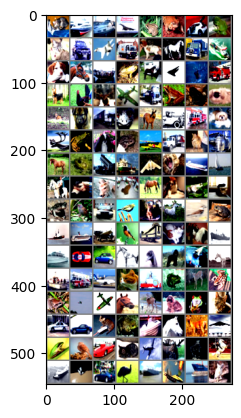

In [81]:
import matplotlib.pyplot as plt
import numpy as np

# functions to show an image

def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# get some random training images
dataiter = iter(testloader)
images, labels = next(dataiter) ## If you run this line, the next data batch is called subsequently.

# show images
imshow(torchvision.utils.make_grid(images))


In [ ]:
# Training settings
lr = 0.1
weight_decay = 5e-4
epochs = 200
best_prec = 0

model = model.to(device)
criterion = nn.CrossEntropyLoss().to(device)
optimizer = torch.optim.SGD(
    model.parameters(), lr=lr, momentum=0.9,
    weight_decay=weight_decay, nesterov=True
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

if not os.path.exists('result'):
    os.makedirs('result')

fdir = 'result/' + str(model_name)
os.makedirs(fdir, exist_ok=True)

for epoch in range(0, epochs):
    # adjust_learning_rate(optimizer, epoch)

    train(trainloader, model, criterion, optimizer, epoch)
    
    # evaluate on test set
    print("Validation starts")
    prec = validate(testloader, model, criterion)

    # remember best precision and save checkpoint
    is_best = prec > best_prec
    best_prec = max(prec, best_prec)
    print('best acc: {:1f}'.format(best_prec))
    save_checkpoint({
        'epoch': epoch + 1,
        'state_dict': model.state_dict(),
        'best_prec': best_prec,
        'optimizer': optimizer.state_dict(),
    }, is_best, fdir)

    scheduler.step()
    print('Learning rate: {:.6f}'.format(optimizer.param_groups[0]['lr']))


In [82]:
# Reload the saved best checkpoint and evaluate it
fdir = 'result/' + str(model_name) + '/model_best.pth.tar'
checkpoint = torch.load(fdir, map_location=device)
model.load_state_dict(checkpoint['state_dict'])


criterion = nn.CrossEntropyLoss().to(device)

model.eval()
model.to(device)


prec = validate(testloader, model, criterion)
print('Final test accuracy: {:.2f}%'.format(prec))


Test: [0/79]	Time 6.152 (6.152)	Loss 0.1314 (0.1314)	Prec 92.969% (92.969%)
 * Prec 92.790% 
Final test accuracy: 92.79%


## HW4 — ResNet-20 Post-Training Weight Quantization

The baseline accuracy above is measured using the original trained checkpoint. The next two cells perform weight-only post-training quantization (PTQ) at 8 bits and 4 bits.

**Alpha choice:** each `Conv2d` layer uses its own `alpha = scale_pct*max(abs(weight))`.

**Scale choice:** we run a **MSE** based search over 0.4 - 1.0 with 1000 candidates for each layer.

Run the baseline cell and then run the 8-bit and 4-bit cells. The test accuracy printed by each cell can be compared with the baseline accuracy.

In [86]:
# Code8-style weight quantization helper
def quantize_weight(weight, w_bit, alpha):
    # self.w_bit = w_bit - 1, then quantize magnitudes with 2**self.w_bit - 1.
    b = w_bit - 1

    if alpha.item() == 0:
        return weight.clone()

    input_d = weight / alpha
    input_c = input_d.clamp(min=-1, max=1)
    sign = input_c.sign()
    input_abs = input_c.abs()

    levels = 2 ** b - 1
    input_q = input_abs.mul(levels).round().div(levels).mul(sign)

    return input_q.mul(alpha)

def find_optimal_alpha_mse(weights, w_bit):
    max_val = weights.abs().max()
   
    best_alpha = max_val
    best_mse = float('inf')
    
    # Test 1000 candidate alphas between 40% and 100% of max value
    for scale_pct in torch.linspace(0.4, 1.0, 1000):
        candidate_alpha = max_val * scale_pct
        dequantized_w = quantize_weight(weights, w_bit, candidate_alpha)
        mse = torch.mean((weights - dequantized_w) ** 2).item()
        
        if mse < best_mse:
            best_mse = mse
            best_alpha = candidate_alpha
            
    return best_alpha

def quantize_conv_weights(model, w_bit, use_mse_search = True):
    quantized_layers = 0
    with torch.no_grad():
        for layer in model.modules():
            if isinstance(layer, torch.nn.Conv2d):
                # Per-layer alpha/clipping value.
                max = layer.weight.detach().abs().max()

                if use_mse_search:
                    alpha = find_optimal_alpha_mse(layer.weight,w_bit)
                    print(f"Layer {quantized_layers+1} alpha choosen: {alpha.item():.4f} (Clipped at {alpha.div(max).mul(100):.2f}% of max)")

                    layer.weight.copy_(quantize_weight(layer.weight, w_bit, alpha))
                else:
                    layer.weight.copy_(quantize_weight(layer.weight, w_bit, max))

                quantized_layers += 1
    return quantized_layers

### 8-bit weight PTQ (with MSE Search for alpha)

In [87]:
# Reload the original trained checkpoint, then apply 8-bit weight PTQ.
checkpoint_path = os.path.join("result", str(model_name), "model_best.pth.tar")
checkpoint = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["state_dict"])
model.to(device)
model.eval()

num_quantized_layers = quantize_conv_weights(model, w_bit=8)

criterion = nn.CrossEntropyLoss().to(device)
print(f"Applied 8-bit PTQ to {num_quantized_layers} Conv2d layers.")
acc_8bit = validate(testloader, model, criterion)
print("Final test accuracy after 8-bit weight PTQ: {:.2f}%".format(acc_8bit))
print("Accuracy change vs. original baseline: {:+.2f} percentage points".format(acc_8bit - prec))


Layer 1 alpha choosen: 0.7746 (Clipped at 99.82% of max)
Layer 2 alpha choosen: 0.4591 (Clipped at 98.86% of max)
Layer 3 alpha choosen: 0.2700 (Clipped at 98.62% of max)
Layer 4 alpha choosen: 0.2509 (Clipped at 100.00% of max)
Layer 5 alpha choosen: 0.3169 (Clipped at 99.94% of max)
Layer 6 alpha choosen: 0.2468 (Clipped at 100.00% of max)
Layer 7 alpha choosen: 0.2927 (Clipped at 99.82% of max)
Layer 8 alpha choosen: 0.2418 (Clipped at 97.54% of max)
Layer 9 alpha choosen: 0.3081 (Clipped at 95.68% of max)
Layer 10 alpha choosen: 0.5136 (Clipped at 99.88% of max)
Layer 11 alpha choosen: 0.2223 (Clipped at 95.98% of max)
Layer 12 alpha choosen: 0.2135 (Clipped at 96.04% of max)
Layer 13 alpha choosen: 0.2233 (Clipped at 98.08% of max)
Layer 14 alpha choosen: 0.2267 (Clipped at 97.24% of max)
Layer 15 alpha choosen: 0.1960 (Clipped at 94.59% of max)
Layer 16 alpha choosen: 0.1782 (Clipped at 92.73% of max)
Layer 17 alpha choosen: 0.2469 (Clipped at 98.62% of max)
Layer 18 alpha choose

### 4-bit weight PTQ (with MSE Search for alpha)

In [88]:
# Reload the original trained checkpoint again, then apply 4-bit weight PTQ.
checkpoint_path = os.path.join("result", str(model_name), "model_best.pth.tar")
checkpoint = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["state_dict"])
model.to(device)
model.eval()

num_quantized_layers = quantize_conv_weights(model, w_bit=4)

criterion = nn.CrossEntropyLoss().to(device)
print(f"Applied 4-bit PTQ to {num_quantized_layers} Conv2d layers.")
acc_4bit = validate(testloader, model, criterion)
print("Final test accuracy after 4-bit weight PTQ: {:.2f}%".format(acc_4bit))
print("Accuracy change vs. original baseline: {:+.2f} percentage points".format(acc_4bit - prec))


Layer 1 alpha choosen: 0.5415 (Clipped at 69.79% of max)
Layer 2 alpha choosen: 0.2234 (Clipped at 48.11% of max)
Layer 3 alpha choosen: 0.1925 (Clipped at 70.33% of max)
Layer 4 alpha choosen: 0.1686 (Clipped at 67.21% of max)
Layer 5 alpha choosen: 0.1647 (Clipped at 51.95% of max)
Layer 6 alpha choosen: 0.1850 (Clipped at 74.95% of max)
Layer 7 alpha choosen: 0.1737 (Clipped at 59.22% of max)
Layer 8 alpha choosen: 0.1484 (Clipped at 59.88% of max)
Layer 9 alpha choosen: 0.1375 (Clipped at 42.70% of max)
Layer 10 alpha choosen: 0.3249 (Clipped at 63.18% of max)
Layer 11 alpha choosen: 0.1206 (Clipped at 52.07% of max)
Layer 12 alpha choosen: 0.0993 (Clipped at 44.68% of max)
Layer 13 alpha choosen: 0.1268 (Clipped at 55.68% of max)
Layer 14 alpha choosen: 0.0940 (Clipped at 40.30% of max)
Layer 15 alpha choosen: 0.1100 (Clipped at 53.09% of max)
Layer 16 alpha choosen: 0.0982 (Clipped at 51.11% of max)
Layer 17 alpha choosen: 0.1466 (Clipped at 58.56% of max)
Layer 18 alpha choosen:

### 8-bit weight PTQ (without MSE Search for alpha)

In [ ]:
# Reload the original trained checkpoint, then apply 8-bit weight PTQ.
checkpoint_path = os.path.join("result", str(model_name), "model_best.pth.tar")
checkpoint = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["state_dict"])
model.to(device)
model.eval()

num_quantized_layers = quantize_conv_weights(model, w_bit=8 , use_mse_search=False)

criterion = nn.CrossEntropyLoss().to(device)
print(f"Applied 8-bit PTQ to {num_quantized_layers} Conv2d layers (without MSE alpha search).")
acc_8bit = validate(testloader, model, criterion)
print("Final test accuracy after 8-bit weight PTQ: {:.2f}%".format(acc_8bit))
print("Accuracy change vs. original baseline: {:+.2f} percentage points".format(acc_8bit - prec))


Applied 8-bit PTQ to without MSE alpha search 21 Conv2d layers.
Test: [0/79]	Time 4.895 (4.895)	Loss 0.1292 (0.1292)	Prec 92.969% (92.969%)
 * Prec 92.820% 
Final test accuracy after 8-bit weight PTQ: 92.82%
Accuracy change vs. original baseline: +0.03 percentage points


### 4-bit weight PTQ (without MSE Search for alpha)

In [92]:
# Reload the original trained checkpoint again, then apply 4-bit weight PTQ.
checkpoint_path = os.path.join("result", str(model_name), "model_best.pth.tar")
checkpoint = torch.load(checkpoint_path, map_location=device)
model.load_state_dict(checkpoint["state_dict"])
model.to(device)
model.eval()

num_quantized_layers = quantize_conv_weights(model, w_bit=4, use_mse_search=False)

criterion = nn.CrossEntropyLoss().to(device)
print(f"Applied 4-bit PTQ to {num_quantized_layers} Conv2d layers (without MSE alpha search).")
acc_4bit = validate(testloader, model, criterion)
print("Final test accuracy after 4-bit weight PTQ: {:.2f}%".format(acc_4bit))
print("Accuracy change vs. original baseline: {:+.2f} percentage points".format(acc_4bit - prec))


Applied 4-bit PTQ to 21 Conv2d layers (without MSE alpha search).
Test: [0/79]	Time 4.979 (4.979)	Loss 0.3682 (0.3682)	Prec 87.500% (87.500%)
 * Prec 87.730% 
Final test accuracy after 4-bit weight PTQ: 87.73%
Accuracy change vs. original baseline: -5.06 percentage points
